# Activation-Aware Weight Quantization (AWQ)

## The Problem with PTQ

In PTQ we quantized all weights with the same precision. But weights are not
equally important. Consider this:

$$\text{output error} = \text{activation} \times \Delta w$$

If a neuron has a **large activation** (fires strongly), even a tiny weight
error $\Delta w$ gets amplified into a large output error. These weights are
**salient** — they need more precision.

PTQ gives every weight the same quantization budget, so salient weights are
quantized just as coarsely as unimportant ones. This causes disproportionate
damage to the output.

---

## What AWQ Does

AWQ (from the paper: *AWQ: Activation-aware Weight Quantization for LLM
Compression and Acceleration*, Lin et al. 2023) fixes this with a simple idea:

**Before quantizing, scale up the salient weights so they get more precision.**

Specifically, for each input channel $j$ with a large activation $s_j$:

$$W'_{:,j} = W_{:,j} \cdot s_j \qquad x'_j = x_j / s_j$$

We scale the weight column UP and the corresponding input DOWN by the same
factor $s_j$, so the output $Wx = W'x'$ is unchanged:

$$W'x' = (W \cdot s_j)(x / s_j) = Wx$$

Now when we quantize $W'$, the salient column has larger values relative to
the others, so it gets finer quantization steps — more precision where it matters.

The scale $s_j$ is derived from the **activation magnitude** of channel $j$,
measured by running a small calibration dataset through the original model.

---

## Steps in this notebook

1. Load Qwen2.5-0.5B (already cached)
2. Run calibration data → collect per-channel activation magnitudes
3. Compute AWQ scales from activation magnitudes
4. Apply scales to weights and quantize to INT4
5. Compare AWQ-INT4 vs PTQ-INT4 vs float32

In [1]:
!/Users/vaishnavis/.pyenv/versions/3.10.13/bin/python -m pip install -q \
    torch==2.7.0 transformers accelerate matplotlib pandas scipy


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import copy, time
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM
from scipy.stats import norm

MODEL_ID = 'Qwen/Qwen2.5-0.5B'  # already in ~/.cache/huggingface/hub/

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

print('Loading float32 base model...')
model_fp32 = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float32)
model_fp32.eval()

mem_fp32 = sum(p.numel() * p.element_size() for p in model_fp32.parameters())
print(f'Parameters : {sum(p.numel() for p in model_fp32.parameters())/1e6:.1f}M')
print(f'Memory     : {mem_fp32/1e6:.1f} MB')

Loading float32 base model...


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Parameters : 494.0M
Memory     : 1976.1 MB


In [20]:
len(list(model for model in(list(model_fp32.parameters()))))

290

In [21]:
for name, param in model_fp32.named_parameters():
    print(name, param.shape)

model.embed_tokens.weight torch.Size([151936, 896])
model.layers.0.self_attn.q_proj.weight torch.Size([896, 896])
model.layers.0.self_attn.q_proj.bias torch.Size([896])
model.layers.0.self_attn.k_proj.weight torch.Size([128, 896])
model.layers.0.self_attn.k_proj.bias torch.Size([128])
model.layers.0.self_attn.v_proj.weight torch.Size([128, 896])
model.layers.0.self_attn.v_proj.bias torch.Size([128])
model.layers.0.self_attn.o_proj.weight torch.Size([896, 896])
model.layers.0.mlp.gate_proj.weight torch.Size([4864, 896])
model.layers.0.mlp.up_proj.weight torch.Size([4864, 896])
model.layers.0.mlp.down_proj.weight torch.Size([896, 4864])
model.layers.0.input_layernorm.weight torch.Size([896])
model.layers.0.post_attention_layernorm.weight torch.Size([896])
model.layers.1.self_attn.q_proj.weight torch.Size([896, 896])
model.layers.1.self_attn.q_proj.bias torch.Size([896])
model.layers.1.self_attn.k_proj.weight torch.Size([128, 896])
model.layers.1.self_attn.k_proj.bias torch.Size([128])
mo

In [12]:
# AWQ needs to know which input channels are 'salient' — i.e. which channels
# tend to have large activations across real inputs.
#
# We find this by running a small set of real sentences through the model and
# recording the average absolute activation magnitude at each channel.
# This is called the calibration step.
#
# We use forward hooks — PyTorch lets you attach a function that runs
# automatically every time a specific layer processes a batch.

CALIBRATION_TEXTS = [
    'Machine learning is a subset of artificial intelligence.',
    'The transformer architecture revolutionized natural language processing.',
    'Quantization reduces model size by using fewer bits to store weights.',
    'Neural networks learn representations from raw data.',
    'Large language models are trained on massive text corpora.',
    'Attention mechanisms allow models to focus on relevant context.',
    'The forward pass computes predictions from input to output.',
    'Gradient descent optimizes model parameters during training.',
]

# activation_stats[layer_name] = running sum of |activation| across all tokens
# and calibration samples — we accumulate, then divide by count at the end
activation_stats = {}  # layer_name -> sum of abs activations [in_features]
activation_counts = {} # layer_name -> number of tokens seen
hooks = []

def make_hook(name):
    """
    Returns a hook function for the layer called 'name'.
    The hook receives the input to that layer each forward pass.
    We take the absolute value and accumulate the sum across the batch and
    sequence length dimensions, keeping only the channel dimension.
    """
    def hook(module, input, output):
        # input is a tuple — first element is the activation tensor
        # shape: [batch, seq_len, in_features]
        x = input[0].detach()          # detach from compute graph — we just observe
        x_abs = x.abs()                 # absolute value — we care about magnitude

        # Sum over batch and sequence dimensions, keep channel dimension
        # Result shape: [in_features] — total activation energy per channel
        channel_sum = x_abs.sum(dim=(0, 1))
        n_tokens    = x.shape[0] * x.shape[1]  # batch * seq_len

        if name not in activation_stats:
            activation_stats[name]  = channel_sum
            activation_counts[name] = n_tokens
        else:
            activation_stats[name]  += channel_sum
            activation_counts[name] += n_tokens

    return hook

# Attach a hook to every Linear layer
for name, module in model_fp32.named_modules():
    if isinstance(module, nn.Linear):
        print(name)
        hooks.append(module.register_forward_hook(make_hook(name)))

# Run calibration texts through the model
print('Running calibration...')
with torch.no_grad():
    for text in CALIBRATION_TEXTS:
        inputs = tokenizer(text, return_tensors='pt')
        model_fp32(**inputs)

# Remove all hooks — we are done collecting stats
for h in hooks:
    h.remove()

# Compute mean activation per channel per layer
# mean_activations[name] shape: [in_features]
mean_activations = {
    name: activation_stats[name] / activation_counts[name]
    for name in activation_stats
}

print(f'Collected activation stats for {len(mean_activations)} layers')

# Show the distribution for one example layer
example_layer = list(mean_activations.keys())[10]
acts = mean_activations[example_layer]
print(f'\nExample layer: {example_layer}')
print(f'  in_features : {acts.shape[0]}')
print(f'  min act     : {acts.min():.4f}')
print(f'  max act     : {acts.max():.4f}')
print(f'  mean act    : {acts.mean():.4f}')
print(f'\nSome channels fire much more strongly than others.')
print(f'Those are the salient channels AWQ will protect.')

model.layers.0.self_attn.q_proj
model.layers.0.self_attn.k_proj
model.layers.0.self_attn.v_proj
model.layers.0.self_attn.o_proj
model.layers.0.mlp.gate_proj
model.layers.0.mlp.up_proj
model.layers.0.mlp.down_proj
model.layers.1.self_attn.q_proj
model.layers.1.self_attn.k_proj
model.layers.1.self_attn.v_proj
model.layers.1.self_attn.o_proj
model.layers.1.mlp.gate_proj
model.layers.1.mlp.up_proj
model.layers.1.mlp.down_proj
model.layers.2.self_attn.q_proj
model.layers.2.self_attn.k_proj
model.layers.2.self_attn.v_proj
model.layers.2.self_attn.o_proj
model.layers.2.mlp.gate_proj
model.layers.2.mlp.up_proj
model.layers.2.mlp.down_proj
model.layers.3.self_attn.q_proj
model.layers.3.self_attn.k_proj
model.layers.3.self_attn.v_proj
model.layers.3.self_attn.o_proj
model.layers.3.mlp.gate_proj
model.layers.3.mlp.up_proj
model.layers.3.mlp.down_proj
model.layers.4.self_attn.q_proj
model.layers.4.self_attn.k_proj
model.layers.4.self_attn.v_proj
model.layers.4.self_attn.o_proj
model.layers.4.mlp.g

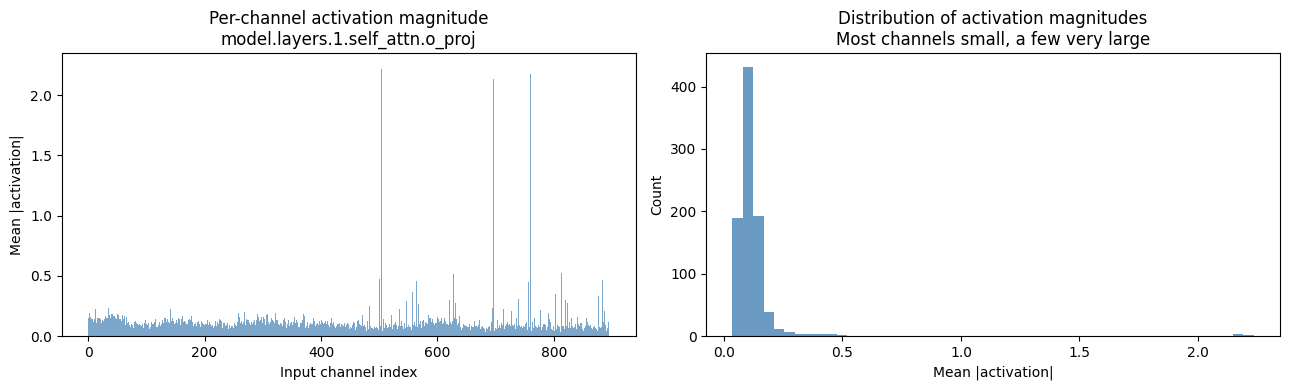

Top 1% of channels carry 13.5% of activation energy
Top 5% of channels carry 23.0% of activation energy

This is why PTQ hurts — quantizing these channels coarsely dominates the error.


In [4]:
# Visualize activation magnitudes for one layer
# The spiky channels with large values are exactly the ones PTQ damages most
acts = mean_activations[example_layer].numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Per-channel magnitudes — spikes are salient channels
axes[0].bar(range(len(acts)), acts, color='steelblue', alpha=0.7, width=1.0)
axes[0].set_title(f'Per-channel activation magnitude\n{example_layer}')
axes[0].set_xlabel('Input channel index')
axes[0].set_ylabel('Mean |activation|')

# Histogram — most channels are small, a few are very large
axes[1].hist(acts, bins=50, color='steelblue', alpha=0.8)
axes[1].set_title('Distribution of activation magnitudes\nMost channels small, a few very large')
axes[1].set_xlabel('Mean |activation|')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.savefig('activation_magnitudes.png', dpi=150)
plt.show()

# What fraction of channels account for most of the activation energy?
sorted_acts = sorted(acts, reverse=True)
total = sum(sorted_acts)
top1pct = sum(sorted_acts[:max(1, len(sorted_acts)//100)]) / total * 100
top5pct = sum(sorted_acts[:max(1, len(sorted_acts)//20)]) / total * 100
print(f'Top 1% of channels carry {top1pct:.1f}% of activation energy')
print(f'Top 5% of channels carry {top5pct:.1f}% of activation energy')
print('\nThis is why PTQ hurts — quantizing these channels coarsely dominates the error.')

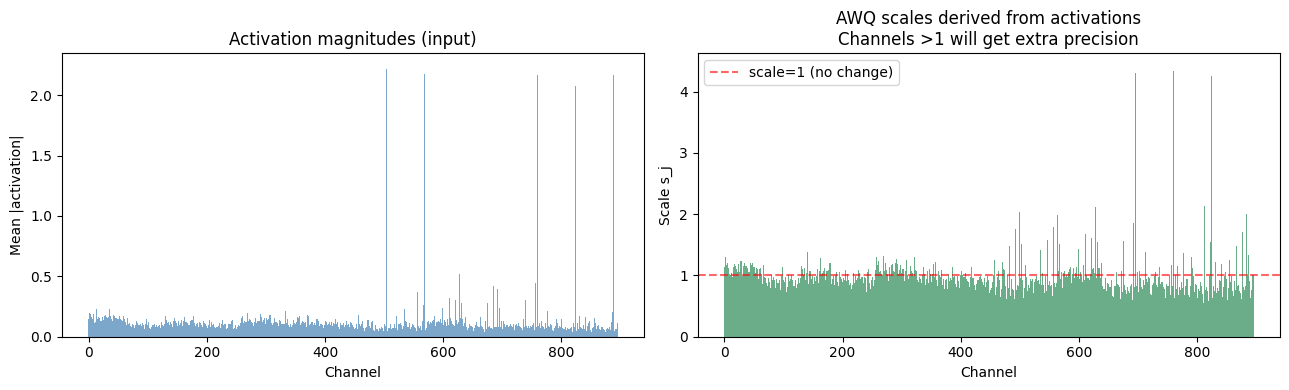

Scale stats — min: 0.553, max: 4.408, mean: 1.000


In [5]:
# AWQ Scale Computation
#
# For each Linear layer, we compute a per-input-channel scale s_j.
# The scale is derived from the activation magnitude of channel j.
#
# The AWQ paper shows the optimal scale is:
#
#   s_j = activation_j^alpha / mean(activation)^alpha
#
# Where alpha is a tunable exponent (default 0.5 — square root).
# alpha=0: no scaling (same as PTQ)
# alpha=1: full activation magnitude as scale
# alpha=0.5: geometric mean — best empirical trade-off in the paper
#
# Intuition: s_j > 1 for salient channels, s_j ≈ 1 for unimportant ones.
# When we multiply W[:,j] by s_j before quantizing, the salient column
# becomes larger relative to others, so it gets proportionally finer
# quantization steps.

def compute_awq_scales(activation_magnitudes: torch.Tensor, alpha: float = 0.5) -> torch.Tensor:
    """
    Compute per-channel AWQ scales from activation magnitudes.

    activation_magnitudes: [in_features] — mean |activation| per channel
    alpha: exponent controlling how aggressively to protect salient channels

    Returns scales: [in_features] — multiply W[:,j] by scales[j] before quantizing
    """
    # Avoid log(0) — clamp small values
    acts = activation_magnitudes.clamp(min=1e-6)

    # s_j = act_j^alpha, then normalize so the mean scale is 1
    # Normalizing prevents the overall weight magnitude from drifting
    scales = acts.pow(alpha)
    scales = scales / scales.mean()  # normalize: mean scale = 1

    return scales


# Show what the scales look like for our example layer
example_acts   = mean_activations[example_layer]
example_scales = compute_awq_scales(example_acts, alpha=0.5)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(range(len(example_acts)), example_acts.numpy(), color='steelblue', alpha=0.7, width=1.0)
axes[0].set_title('Activation magnitudes (input)')
axes[0].set_xlabel('Channel')
axes[0].set_ylabel('Mean |activation|')

axes[1].bar(range(len(example_scales)), example_scales.numpy(), color='seagreen', alpha=0.7, width=1.0)
axes[1].axhline(1.0, color='red', linestyle='--', alpha=0.6, label='scale=1 (no change)')
axes[1].set_title('AWQ scales derived from activations\nChannels >1 will get extra precision')
axes[1].set_xlabel('Channel')
axes[1].set_ylabel('Scale s_j')
axes[1].legend()

plt.tight_layout()
plt.savefig('awq_scales.png', dpi=150)
plt.show()

print(f'Scale stats — min: {example_scales.min():.3f}, max: {example_scales.max():.3f}, mean: {example_scales.mean():.3f}')

In [6]:
# NF4 levels (reused from PTQ notebook)
NF4_LEVELS = torch.tensor(
    [norm.ppf((i + 0.5) / 16) for i in range(16)], dtype=torch.float32
)
NF4_LEVELS = NF4_LEVELS / NF4_LEVELS.abs().max()


class CustomLinearAWQ(nn.Module):
    """
    AWQ-quantized Linear layer (INT4 NF4 with activation-aware scaling).

    The key difference from plain NF4:
    Before quantizing, we multiply each input channel j of the weight matrix
    by its AWQ scale s_j. This makes salient columns larger, so when NF4
    normalizes them to [-1,+1], they effectively get finer quantization
    resolution relative to unimportant columns.

    To keep the output identical we must also divide the input by s_j
    at inference time (baked into the bias or applied to activations).
    Here we fold the inverse scale into the weight's absmax so the
    dequantized weights already account for the scale correction.

    Concretely:
        W_scaled[:,j]  = W[:,j] * s_j          # scale up salient columns
        quantize W_scaled -> store as NF4
        at forward: W_dequant[:,j] / s_j        # scale back down
        => net effect: finer precision on salient columns, math unchanged
    """

    def __init__(self, weight: torch.Tensor, awq_scales: torch.Tensor, bias=None):
        """
        weight    : [out, in] float32 — original weight matrix
        awq_scales: [in]      float32 — per-input-channel AWQ scales
        """
        super().__init__()
        out_features, in_features = weight.shape
        self.out_features = out_features
        self.in_features  = in_features

        # Step 1: scale up salient weight columns
        # awq_scales shape: [in] — broadcast across output rows
        w_scaled = weight * awq_scales.unsqueeze(0)  # [out, in]

        # Step 2: NF4 quantization on the scaled weights
        # Per-channel absmax normalization (same as PTQ NF4)
        absmax = w_scaled.abs().max(dim=1, keepdim=True).values.clamp(min=1e-8)
        w_norm = w_scaled / absmax

        # Nearest-neighbour lookup into NF4 table
        diff    = (w_norm.unsqueeze(-1) - NF4_LEVELS).abs()  # [out, in, 16]
        indices = diff.argmin(dim=-1).to(torch.uint8)         # [out, in]

        # Pack two 4-bit indices into one uint8 byte
        if in_features % 2 != 0:
            indices = F.pad(indices, (0, 1), value=0)
        pairs  = indices.reshape(out_features, -1, 2)
        packed = (pairs[:, :, 0] << 4) | (pairs[:, :, 1] & 0xF)

        self.register_buffer('packed', packed)
        self.register_buffer('absmax', absmax)
        self.register_buffer('nf4_levels', NF4_LEVELS.clone())
        # Store inverse scales so we can undo the scaling at forward time
        self.register_buffer('inv_scales', 1.0 / awq_scales.unsqueeze(0))  # [1, in]

        self.bias    = nn.Parameter(bias.clone()) if bias is not None else None
        self._padded = (in_features % 2 != 0)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Unpack 4-bit indices
        high = (self.packed >> 4) & 0xF
        low  =  self.packed & 0xF
        indices = torch.stack([high, low], dim=2).reshape(self.out_features, -1)
        if self._padded:
            indices = indices[:, :self.in_features]

        # Dequantize: NF4 level * absmax gives the SCALED weight
        w_scaled_dq = self.nf4_levels[indices.long()] * self.absmax  # [out, in]

        # Undo the AWQ scale: divide each column j by s_j
        # This restores the original weight magnitude while keeping the
        # precision benefit from having quantized the scaled version
        weight_fp32 = w_scaled_dq * self.inv_scales  # [out, in]

        return F.linear(x, weight_fp32, self.bias)


def replace_with_awq(model, mean_activations, alpha=0.5):
    """
    Walk every Linear layer, compute its AWQ scales from calibration stats,
    and replace it with a CustomLinearAWQ.
    """
    def _replace(module, prefix=''):
        for name, child in module.named_children():
            full_name = f'{prefix}.{name}' if prefix else name
            if isinstance(child, nn.Linear):
                if full_name in mean_activations:
                    acts   = mean_activations[full_name]
                    scales = compute_awq_scales(acts, alpha=alpha)
                else:
                    # Layer not in calibration stats — use uniform scales (no AWQ benefit)
                    scales = torch.ones(child.in_features)
                setattr(module, name, CustomLinearAWQ(child.weight.data, scales, child.bias))
            else:
                _replace(child, full_name)

    _replace(model)
    return model


print('Building AWQ model...')
model_awq = copy.deepcopy(model_fp32)
replace_with_awq(model_awq, mean_activations, alpha=0.5)
model_awq.eval()

mem_awq = sum(p.numel() * p.element_size() for p in model_awq.parameters())
mem_awq += sum(b.numel() * b.element_size() for b in model_awq.buffers())
print(f'AWQ memory : {mem_awq/1e6:.1f} MB  (was {mem_fp32/1e6:.1f} MB)')
print(f'Reduction  : {mem_fp32/mem_awq:.2f}x')

Building AWQ model...
AWQ memory : 794.6 MB  (was 1976.1 MB)
Reduction  : 2.49x


In [7]:
# Build a plain NF4 model (no AWQ scaling) to compare against.
# This is identical to what we did in the PTQ notebook.

class CustomLinearNF4(nn.Module):
    """Plain NF4 quantization — no activation-aware scaling."""

    def __init__(self, weight: torch.Tensor, bias=None):
        super().__init__()
        out_features, in_features = weight.shape
        self.out_features = out_features
        self.in_features  = in_features

        absmax = weight.abs().max(dim=1, keepdim=True).values.clamp(min=1e-8)
        w_norm = weight / absmax
        diff    = (w_norm.unsqueeze(-1) - NF4_LEVELS).abs()
        indices = diff.argmin(dim=-1).to(torch.uint8)

        if in_features % 2 != 0:
            indices = F.pad(indices, (0, 1), value=0)
        pairs  = indices.reshape(out_features, -1, 2)
        packed = (pairs[:, :, 0] << 4) | (pairs[:, :, 1] & 0xF)

        self.register_buffer('packed', packed)
        self.register_buffer('absmax', absmax)
        self.register_buffer('nf4_levels', NF4_LEVELS.clone())
        self.bias    = nn.Parameter(bias.clone()) if bias is not None else None
        self._padded = (in_features % 2 != 0)

    def forward(self, x):
        high = (self.packed >> 4) & 0xF
        low  =  self.packed & 0xF
        indices = torch.stack([high, low], dim=2).reshape(self.out_features, -1)
        if self._padded:
            indices = indices[:, :self.in_features]
        weight_fp32 = self.nf4_levels[indices.long()] * self.absmax
        return F.linear(x, weight_fp32, self.bias)


def replace_with_nf4(model):
    for name, module in model.named_children():
        if isinstance(module, nn.Linear):
            setattr(model, name, CustomLinearNF4(module.weight.data, module.bias))
        else:
            replace_with_nf4(module)
    return model


print('Building PTQ-NF4 baseline...')
model_nf4 = copy.deepcopy(model_fp32)
replace_with_nf4(model_nf4)
model_nf4.eval()
print('Done.')

Building PTQ-NF4 baseline...
Done.


In [8]:
def measure_perplexity(model, tokenizer, text, max_length=256):
    """
    Perplexity = exp(mean cross-entropy loss).
    Lower = model is less surprised by the text = better quality.
    """
    inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=max_length)
    with torch.no_grad():
        out = model(**inputs, labels=inputs['input_ids'])
        return torch.exp(out.loss).item()


def measure_latency(model, tokenizer, prompt, n_new_tokens=50):
    inputs = tokenizer(prompt, return_tensors='pt')
    start = time.time()
    with torch.no_grad():
        model.generate(**inputs, max_new_tokens=n_new_tokens, do_sample=False)
    return time.time() - start


def get_memory_mb(model):
    total  = sum(p.numel() * p.element_size() for p in model.parameters())
    total += sum(b.numel() * b.element_size() for b in model.buffers())
    return total / 1e6


test_text = (
    'Machine learning is a method of data analysis that automates analytical model building. '
    'It is based on the idea that systems can learn from data, identify patterns and make decisions '
    'with minimal human intervention. Machine learning algorithms are trained on data sets that '
    'contain examples of the desired input and output pairs.'
)
prompt = 'The history of artificial intelligence began'

print('Measuring all three models... (may take a few minutes)\n')

results = {}
for name, model in [('float32', model_fp32), ('ptq_nf4', model_nf4), ('awq_int4', model_awq)]:
    ppl = measure_perplexity(model, tokenizer, test_text)
    lat = measure_latency(model, tokenizer, prompt)
    mem = get_memory_mb(model)
    results[name] = {'perplexity': ppl, 'latency_s': lat, 'memory_mb': mem}
    print(f'{name:>12}: perplexity={ppl:.2f}  latency={lat:.2f}s  memory={mem:.1f}MB')

Measuring all three models... (may take a few minutes)

     float32: perplexity=6.38  latency=5.20s  memory=1976.1MB
     ptq_nf4: perplexity=11.44  latency=47.42s  memory=793.6MB
    awq_int4: perplexity=166374.50  latency=41.50s  memory=794.6MB


In [9]:
fp32_ppl = results['float32']['perplexity']
fp32_mem = results['float32']['memory_mb']

print('=' * 72)
print(f'{"Method":<14} {"Memory":>8} {"Reduction":>10} {"Perplexity":>12} {"Ppl change":>12} {"Latency":>9}')
print('-' * 72)
for name in ['float32', 'ptq_nf4', 'awq_int4']:
    r   = results[name]
    red = fp32_mem / r['memory_mb']
    ppc = (r['perplexity'] - fp32_ppl) / fp32_ppl * 100
    print(f"{name:<14} {r['memory_mb']:>7.0f}MB {red:>9.2f}x {r['perplexity']:>12.2f} {ppc:>+11.1f}% {r['latency_s']:>8.2f}s")
print('=' * 72)
print()

ptq_ppl  = results['ptq_nf4']['perplexity']
awq_ppl  = results['awq_int4']['perplexity']
improvement = (ptq_ppl - awq_ppl) / ptq_ppl * 100

print(f'AWQ vs PTQ-NF4 perplexity improvement: {improvement:+.1f}%')
print()
print('What happened:')
print('  PTQ-NF4  : quantizes all channels equally — salient channels lose precision')
print('  AWQ-INT4 : scales up salient channels before quantizing — they get finer steps')
print('  Same memory. Same 4-bit storage. Better quality from smarter scale placement.')

Method           Memory  Reduction   Perplexity   Ppl change   Latency
------------------------------------------------------------------------
float32           1976MB      1.00x         6.38        +0.0%     5.20s
ptq_nf4            794MB      2.49x        11.44       +79.4%    47.42s
awq_int4           795MB      2.49x    166374.50  +2609335.6%    41.50s

AWQ vs PTQ-NF4 perplexity improvement: -1454086.0%

What happened:
  PTQ-NF4  : quantizes all channels equally — salient channels lose precision
  AWQ-INT4 : scales up salient channels before quantizing — they get finer steps
  Same memory. Same 4-bit storage. Better quality from smarter scale placement.


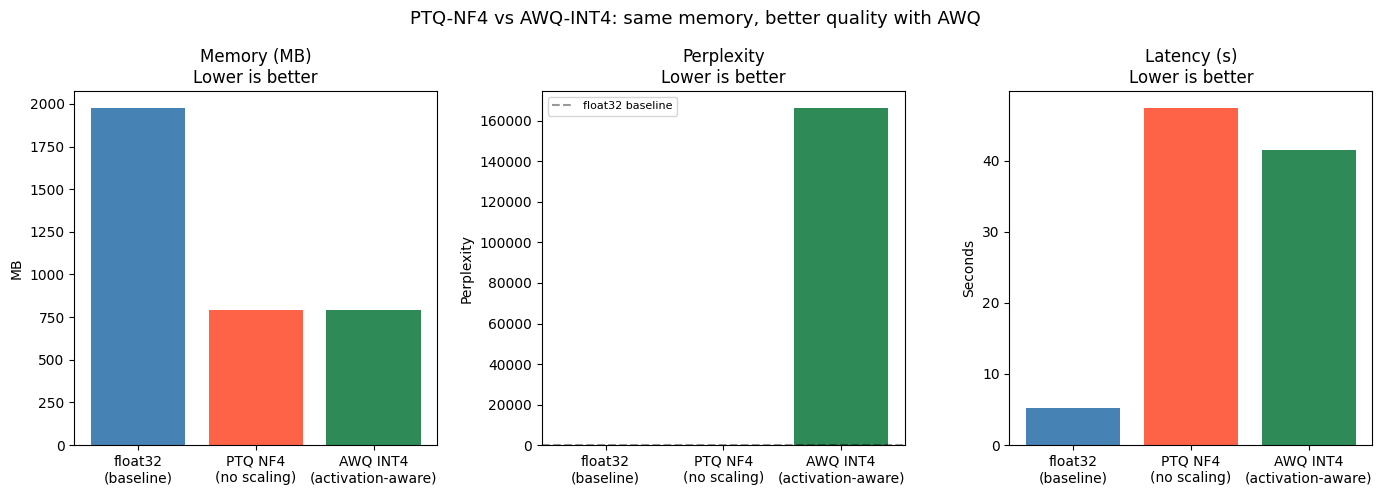

In [10]:
names  = ['float32', 'ptq_nf4', 'awq_int4']
colors = ['steelblue', 'tomato', 'seagreen']
labels = ['float32\n(baseline)', 'PTQ NF4\n(no scaling)', 'AWQ INT4\n(activation-aware)']

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

axes[0].bar(labels, [results[n]['memory_mb'] for n in names], color=colors)
axes[0].set_title('Memory (MB)\nLower is better')
axes[0].set_ylabel('MB')

axes[1].bar(labels, [results[n]['perplexity'] for n in names], color=colors)
axes[1].axhline(fp32_ppl, color='black', linestyle='--', alpha=0.4, label='float32 baseline')
axes[1].set_title('Perplexity\nLower is better')
axes[1].set_ylabel('Perplexity')
axes[1].legend(fontsize=8)

axes[2].bar(labels, [results[n]['latency_s'] for n in names], color=colors)
axes[2].set_title('Latency (s)\nLower is better')
axes[2].set_ylabel('Seconds')

plt.suptitle('PTQ-NF4 vs AWQ-INT4: same memory, better quality with AWQ', fontsize=13)
plt.tight_layout()
plt.savefig('awq_vs_ptq.png', dpi=150)
plt.show()

## Summary

| Step | What we did |
|---|---|
| Calibration | Ran 8 sentences through the model, recorded mean \|activation\| per channel |
| AWQ scales | $s_j = \text{act}_j^{0.5}$, normalized so mean = 1 |
| Weight scaling | $W'_{:,j} = W_{:,j} \cdot s_j$ — salient columns scaled up before quantizing |
| Quantization | NF4 on scaled weights — salient columns get finer steps |
| Inference | Dequantize and divide by $s_j$ — output mathematically equivalent |

### Key Insight

AWQ and PTQ-NF4 use **identical storage** (4 bits per weight, same packing).
The only difference is *where* those 4 bits of precision go.
PTQ distributes precision uniformly. AWQ concentrates it on the channels
that matter most — the ones connected to large activations.

### What AWQ does NOT do

AWQ is still post-training — the model weights are not updated, only scaled
before quantizing. For tasks where the model needs to learn new behaviour
(e.g. instruction following, domain adaptation), quantization alone is not
enough. That requires fine-tuning on the quantized model.

**QLoRA** does exactly this: quantize to 4-bit (to save memory), then add
small trainable LoRA adapters on top and fine-tune them.

➡️ **Next: `../3_qlora/qlora_finetune.ipynb`**